In [42]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn.datasets as datasets
import pandas as pd
import pickle

## Dataset

In [43]:
x, y = datasets.make_moons(n_samples = 500, noise = 0.05)

In [44]:
print(f'{x.shape = }, {y.shape = }')

x.shape = (500, 2), y.shape = (500,)


In [45]:
pd.DataFrame({'x_1' : x[:,0], 'x_2' : x[:,1], 'y' : y})

,x_1,x_2,y
0,1.391375,-0.516696,1
1,-0.992996,0.252729,0
2,0.726795,-0.393723,1
3,1.242034,-0.417113,1
4,1.103071,-0.428052,1
...,...,...,...
495,0.611112,0.857917,0
496,1.985604,0.319686,1
497,-0.223971,0.936492,0
498,0.387339,-0.229235,1


In [46]:
unique = np.unique(y, return_counts = True)
for label, qtd_label in zip(unique[0], unique[1]):
    print(f'Label: {label}\t Counts: {qtd_label}')

Label: 0	 Counts: 250
Label: 1	 Counts: 250


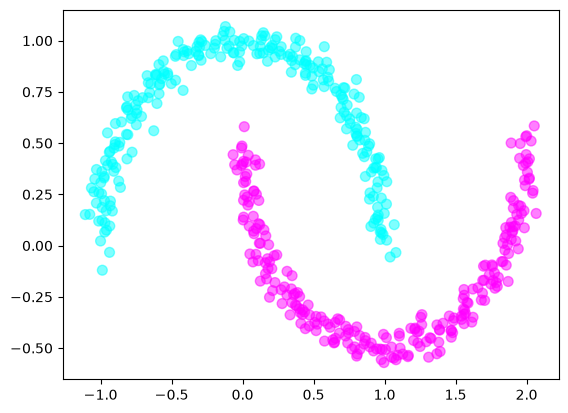

In [47]:
plt.scatter(x[:,0], x[:,1], c = y, s = 50, alpha=0.5, cmap='cool')

## Modelo

- Inicialização dos pesos e bias
- Feedforward
- Cálculo de perda
- Backpropagation
 - Fit

In [ ]:
import numpy as np

class NnModel:
    def __init__(self, x: np.ndarray, y: np.ndarray, hidden_neurons: int = 10, output_neurons: int = 2):
        np.random.seed(8)
        self.x = x
        self.y = y
        self.hidden_neurons = hidden_neurons
        self.output_neurons = output_neurons
        self.input_neurons = self.x.shape[1]

        # Inicializa os pesos e bias (Xavier Initialization)
        self.W1 = np.random.randn(self.input_neurons, self.hidden_neurons) / np.sqrt(self.input_neurons)
        self.B1 = np.zeros((1, self.hidden_neurons))
        self.W2 = np.random.randn(self.hidden_neurons, self.output_neurons) / np.sqrt(self.hidden_neurons) 
        self.B2 = np.zeros((1, self.output_neurons))
        self.model_dict = {'W1': self.W1, 'B1': self.B1, 'W2': self.W2, 'B2': self.B2}
        self.z1 = 0
        self.f1 = 0

    def forward(self, x: np.ndarray) -> np.ndarray:
        # Equação da reta (1)
        self.z1 = x.dot(self.W1) + self.B1

        # Função de ativação (1)
        self.f1 = np.tanh(self.z1)

        # Equação da reta (2)
        z2 = self.f1.dot(self.W2) + self.B2

        # Softmax
        exp_values = np.exp(z2)
        softmax = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        return softmax

    def loss(self, softmax):
        # Cross Entropy
        predictions = np.zeros(self.y.shape[0])
        for i, correct_index in enumerate(self.y):
            predictions[i] = softmax[i][correct_index]

        # CORREÇÃO: Somar o log de todas as predições em vez de pegar apenas a última iteração do loop
        log_prob = np.sum(-np.log(predictions))
        return log_prob / self.y.shape[0]

    def backpropagation(self, softmax: np.ndarray, learning_rate: float) -> None:
        delta2 = np.copy(softmax)
        delta2[range(self.x.shape[0]), self.y] -= 1
        
        dW2 = (self.f1.T).dot(delta2)
        dB2 = np.sum(delta2, axis=0, keepdims=True)
        
        delta1 = delta2.dot(self.W2.T) * (1 - np.power(np.tanh(self.z1), 2))
        dW1 = (self.x.T).dot(delta1)
        dB1 = np.sum(delta1, axis=0, keepdims=True)
        
        # Atualização dos pesos e bias
        self.W1 += -learning_rate * dW1
        self.W2 += -learning_rate * dW2
        self.B1 += -learning_rate * dB1
        self.B2 += -learning_rate * dB2

    def show_plt(self, predictions):
        if self.x.shape[1] != 2:
            return

        plt.scatter(self.x[:,0], self.x[:,1], s = 50, c = predictions, cmap='cool', alpha=0.7)
        plt.show()


    # CORREÇÃO: Indentação alinhada para pertencer à classe NnModel
    def fit(self, epochs: int, lr: float):

        for epoch in range(epochs):

            outputs = self.forward(self.x)
            loss = self.loss(outputs)
            self.backpropagation(softmax=outputs, learning_rate=lr)

            # CORREÇÃO: Utilizar self.y no lugar de y
            prediction = np.argmax(outputs, axis=1)
            correct = (prediction == self.y).sum()
            accuracy = correct / self.y.shape[0]
            

            if int((epoch + 1) % (epochs / 10)) == 0:
                print(f'Epoch: [{epoch + 1} / {epochs}] Accuracy: {accuracy:.3f} Loss: {loss:.5f}')
        
        # CORREÇÃO: O return deve ficar dentro do método fit
        return prediction

# Testando o modelo fora da classe
# Supondo que x e y já estejam definidos previamente
# model = NnModel(x, y, hidden_neurons=10, output_neurons=2)
# result = model.fit(epochs=1000, lr=0.01)

In [49]:
hidden_neurons = 10
output_neurons = 2
learning_rate = 0.001
epochs = 100

In [50]:
model = NnModel(x, y, hidden_neurons=hidden_neurons, output_neurons=output_neurons)
result = model.fit(epochs=epochs, lr=learning_rate)

Epoch: [10 / 100] Accuracy: 0.778 Loss: 0.41955
Epoch: [20 / 100] Accuracy: 0.858 Loss: 0.32411
Epoch: [30 / 100] Accuracy: 0.882 Loss: 0.27634
Epoch: [40 / 100] Accuracy: 0.894 Loss: 0.25102
Epoch: [50 / 100] Accuracy: 0.904 Loss: 0.23417
Epoch: [60 / 100] Accuracy: 0.908 Loss: 0.22037
Epoch: [70 / 100] Accuracy: 0.916 Loss: 0.20754
Epoch: [80 / 100] Accuracy: 0.920 Loss: 0.19487
Epoch: [90 / 100] Accuracy: 0.922 Loss: 0.18212
Epoch: [100 / 100] Accuracy: 0.928 Loss: 0.16936


## Testes e resultados


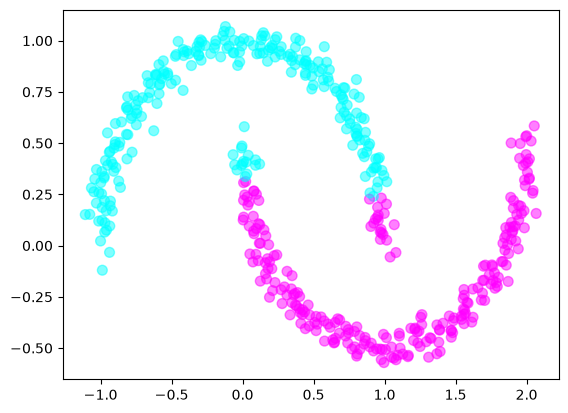

In [51]:
plt.scatter(x[:,0], x[:,1], c = result, s = 50, alpha=0.5, cmap='cool')

## Cluster Dataset


In [52]:
x_, y_ = datasets.make_blobs(n_samples=400, n_features=2, centers=4, random_state=10, cluster_std=0.9, shuffle=True)

In [53]:
x_.shape, y_.shape

((400, 2), (400,))

In [54]:
np.unique(y_, return_counts=True)

(array([0, 1, 2, 3]), array([100, 100, 100, 100]))

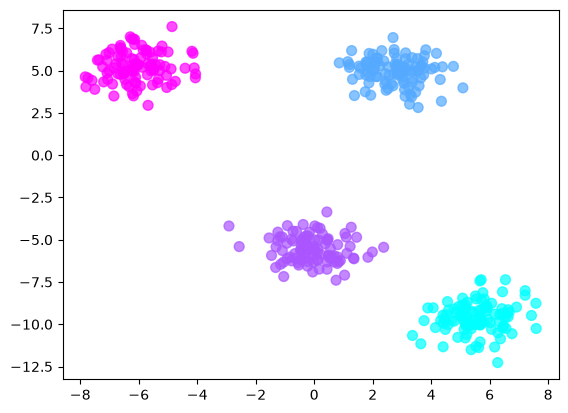

In [55]:
plt.scatter(x_[:,0], x_[:,1], s = 50, c = y_, cmap='cool', alpha=0.7)

In [56]:
hidden_neurons = 8
output_neurons = 4
learning_rate = 0.002
epochs = 50

In [57]:
model = NnModel(x_, y_, hidden_neurons=hidden_neurons, output_neurons=output_neurons)
result = model.fit(epochs=100, lr=0.001)

Epoch: [10 / 100] Accuracy: 0.985 Loss: 0.20998
Epoch: [20 / 100] Accuracy: 0.988 Loss: 0.10925
Epoch: [30 / 100] Accuracy: 0.988 Loss: 0.07701
Epoch: [40 / 100] Accuracy: 0.988 Loss: 0.06129
Epoch: [50 / 100] Accuracy: 0.993 Loss: 0.05189
Epoch: [60 / 100] Accuracy: 0.993 Loss: 0.04557
Epoch: [70 / 100] Accuracy: 0.993 Loss: 0.04102
Epoch: [80 / 100] Accuracy: 0.993 Loss: 0.03760
Epoch: [90 / 100] Accuracy: 0.993 Loss: 0.03494
Epoch: [100 / 100] Accuracy: 0.993 Loss: 0.03281


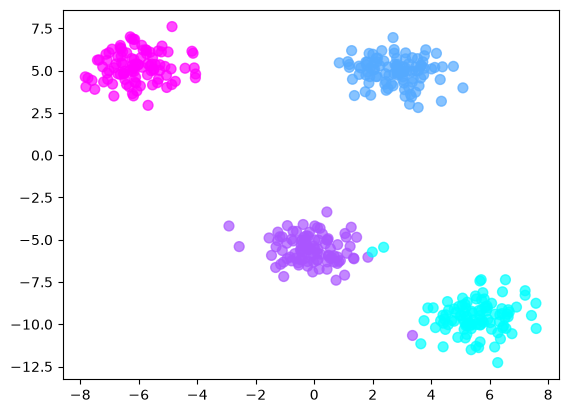

In [58]:
plt.scatter(x_[:,0], x_[:,1], s = 50, c = result, cmap='cool', alpha=0.7)